Import libraries


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

from datetime import datetime

print("Libraries imported successfully!")

Libraries imported successfully!


Generate insurance claims data

In [ ]:
import random

np.random.seed(42)
random.seed(42)

n = 1000

claims = pd.DataFrame({

    "claim_id": [f"CLM{i:05d}" for i in range(1, n+1)],

    "policy_id": [
        f"POL{random.randint(1000, 1300)}"
        for _ in range(n)
    ],

    "customer_age": np.random.randint(18, 75, n),

    "claim_type": np.random.choice(
        ["Health", "Motor", "Property", "Travel"],
        n
    ),

    "region": np.random.choice(
        ["Bangalore", "Mumbai", "Pune",
         "Hyderabad", "Chennai"],
        n
    ),

    "claim_amount": np.random.randint(5000, 200000, n),

    "status": np.random.choice(
        ["Approved", "Rejected", "Pending"],
        n,
        p=[0.60, 0.20, 0.20]
    ),

    "fraud_flag": np.random.choice(
        ["Yes", "No"],
        n,
        p=[0.05, 0.95]
    )
})

# Generate dates
claims["incident_date"] = pd.to_datetime(
    np.random.choice(
        pd.date_range("2025-01-01", "2025-12-31"),
        n
    )
)

claims["reported_date"] = (
    claims["incident_date"] +
    pd.to_timedelta(np.random.randint(1, 15, n), unit="D")
)

claims["claim_date"] = claims["reported_date"]

claims["approved_amount"] = np.where(
    claims["status"] == "Approved",
    claims["claim_amount"] * np.random.uniform(0.5, 1, n),
    0
).round(2)

claims["processing_days"] = np.random.randint(1, 31, n)

claims.head()

,claim_id,policy_id,customer_age,claim_type,region,claim_amount,status,fraud_flag,incident_date,reported_date,claim_date,approved_amount,processing_days
0,CLM00001,POL1057,56,Health,Pune,124246,Pending,No,2025-08-24,2025-09-02,2025-09-02,0.00,22
1,CLM00002,POL1012,69,Motor,Chennai,60731,Approved,No,2025-12-26,2026-01-02,2026-01-02,31219.42,12
2,CLM00003,POL1140,46,Health,Mumbai,160930,Approved,No,2025-02-03,2025-02-15,2025-02-15,110665.23,16
3,CLM00004,POL1125,32,Motor,Bangalore,184761,Rejected,No,2025-12-11,2025-12-13,2025-12-13,0.00,19
4,CLM00005,POL1114,60,Property,Hyderabad,49638,Pending,No,2025-02-14,2025-02-18,2025-02-18,0.00,8


Introduce data-quality problems

In [ ]:
# Missing values
claims.loc[10:19, "customer_age"] = np.nan
claims.loc[30:39, "region"] = np.nan

# Duplicate records
claims = pd.concat(
    [claims, claims.iloc[0:10]],
    ignore_index=True
)

# Invalid claim amounts
claims.loc[50:54, "claim_amount"] = -5000

# Invalid customer ages
claims.loc[60:64, "customer_age"] = 150

# Incorrect reporting dates
claims.loc[70:74, "reported_date"] = (
    claims.loc[70:74, "incident_date"]
    - pd.Timedelta(days=5)
)

print("Dataset created successfully!")
print("Total records:", len(claims))

Dataset created successfully!
Total records: 1010


Explore the dataset

In [ ]:
# Display first five records
display(claims.head())

# Dataset dimensions
print("Rows and columns:", claims.shape)

# Column information
claims.info()

# Statistical summary
display(claims.describe())

# Missing values
print("\nMissing values:")
print(claims.isnull().sum())

# Duplicate records
print("\nDuplicate records:")
print(claims.duplicated().sum())

,claim_id,policy_id,customer_age,claim_type,region,claim_amount,status,fraud_flag,incident_date,reported_date,claim_date,approved_amount,processing_days
0,CLM00001,POL1057,56.0,Health,Pune,124246,Pending,No,2025-08-24,2025-09-02,2025-09-02,0.00,22
1,CLM00002,POL1012,69.0,Motor,Chennai,60731,Approved,No,2025-12-26,2026-01-02,2026-01-02,31219.42,12
2,CLM00003,POL1140,46.0,Health,Mumbai,160930,Approved,No,2025-02-03,2025-02-15,2025-02-15,110665.23,16
3,CLM00004,POL1125,32.0,Motor,Bangalore,184761,Rejected,No,2025-12-11,2025-12-13,2025-12-13,0.00,19
4,CLM00005,POL1114,60.0,Property,Hyderabad,49638,Pending,No,2025-02-14,2025-02-18,2025-02-18,0.00,8


Rows and columns: (1010, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1010 entries, 0 to 1009
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   claim_id         1010 non-null   object        
 1   policy_id        1010 non-null   object        
 2   customer_age     1000 non-null   float64       
 3   claim_type       1010 non-null   object        
 4   region           1000 non-null   object        
 5   claim_amount     1010 non-null   int64         
 6   status           1010 non-null   object        
 7   fraud_flag       1010 non-null   object        
 8   incident_date    1010 non-null   datetime64[ns]
 9   reported_date    1010 non-null   datetime64[ns]
 10  claim_date       1010 non-null   datetime64[ns]
 11  approved_amount  1010 non-null   float64       
 12  processing_days  1010 non-null   int64         
dtypes: datetime64[ns](3), float64(2), int64(2), object(6)
memory usa

,customer_age,claim_amount,incident_date,reported_date,claim_date,approved_amount,processing_days
count,1000.000000,1010.000000,1010,1010,1010,1010.000000,1010.000000
mean,46.777000,102597.402970,2025-06-25 22:21:37.425742336,2025-07-03 03:43:50.495049216,2025-07-03 05:26:29.702970112,44206.500594,15.639604
min,18.000000,-5000.000000,2025-01-01 00:00:00,2025-01-02 00:00:00,2025-01-02 00:00:00,0.000000,1.000000
25%,33.000000,53802.750000,2025-03-26 00:00:00,2025-04-02 06:00:00,2025-04-02 06:00:00,0.000000,9.000000
50%,47.000000,100831.500000,2025-06-25 12:00:00,2025-07-01 00:00:00,2025-07-01 00:00:00,21554.430000,15.000000
75%,61.000000,153892.750000,2025-09-28 00:00:00,2025-10-03 00:00:00,2025-10-03 18:00:00,84612.797500,23.000000
max,150.000000,199994.000000,2025-12-31 00:00:00,2026-01-14 00:00:00,2026-01-14 00:00:00,197165.470000,30.000000
std,17.798653,57753.371221,NaN,NaN,NaN,50761.707246,8.569706



Missing values:
claim_id            0
policy_id           0
customer_age       10
claim_type          0
region             10
claim_amount        0
status              0
fraud_flag          0
incident_date       0
reported_date       0
claim_date          0
approved_amount     0
processing_days     0
dtype: int64

Duplicate records:
10


Remove duplicates

In [ ]:
print("Before cleaning:", len(claims))

claims = claims.drop_duplicates(
    subset=["claim_id"]
)

print("After removing duplicates:", len(claims))

Before cleaning: 1010
After removing duplicates: 1000


Handle missing values

In [ ]:
# Fill missing customer age with median
claims["customer_age"] = claims["customer_age"].fillna(
    claims["customer_age"].median()
)

# Fill missing region with Unknown
claims["region"] = claims["region"].fillna("Unknown")

print(claims.isnull().sum())

claim_id           0
policy_id          0
customer_age       0
claim_type         0
region             0
claim_amount       0
status             0
fraud_flag         0
incident_date      0
reported_date      0
claim_date         0
approved_amount    0
processing_days    0
dtype: int64


Validate incorrect records

In [ ]:
# Identify invalid ages
invalid_age = claims[
    (claims["customer_age"] < 18) |
    (claims["customer_age"] > 100)
]

# Identify invalid claim amounts
invalid_amount = claims[
    claims["claim_amount"] <= 0
]

# Identify reporting date errors
invalid_dates = claims[
    claims["reported_date"] < claims["incident_date"]
]

print("Invalid age records:", len(invalid_age))
print("Invalid amount records:", len(invalid_amount))
print("Invalid date records:", len(invalid_dates))

Invalid age records: 5
Invalid amount records: 5
Invalid date records: 5


Correct invalid records

In [ ]:
claims["data_quality_issue"] = ""

claims.loc[
    (claims["customer_age"] < 18) |
    (claims["customer_age"] > 100),
    "data_quality_issue"
] += "Invalid age; "

claims.loc[
    claims["claim_amount"] <= 0,
    "data_quality_issue"
] += "Invalid claim amount; "

claims.loc[
    claims["reported_date"] < claims["incident_date"],
    "data_quality_issue"
] += "Invalid reporting date; "

# Save records needing investigation
issues = claims[
    claims["data_quality_issue"] != ""
].copy()

# Create an analysis-ready dataset
clean_claims = claims[
    claims["data_quality_issue"] == ""
].copy()

print("Original unique claims:", len(claims))
print("Records requiring investigation:", len(issues))
print("Valid claims:", len(clean_claims))

Original unique claims: 1000
Records requiring investigation: 15
Valid claims: 985


**Exploratory Data Analysis (EDA)**

Key business metrics

In [ ]:
total_claims = len(clean_claims)

total_claim_amount = clean_claims["claim_amount"].sum()

total_approved_amount = clean_claims["approved_amount"].sum()

approved_claims = (
    clean_claims["status"] == "Approved"
).sum()

rejected_claims = (
    clean_claims["status"] == "Rejected"
).sum()

pending_claims = (
    clean_claims["status"] == "Pending"
).sum()

approval_rate = (
    approved_claims / total_claims
) * 100

average_processing_days = (
    clean_claims["processing_days"].mean()
)

print("Total Claims:", total_claims)
print("Total Claim Amount:", total_claim_amount)
print("Total Approved Amount:", round(total_approved_amount, 2))
print("Approved Claims:", approved_claims)
print("Rejected Claims:", rejected_claims)
print("Pending Claims:", pending_claims)
print("Approval Rate:", round(approval_rate, 2), "%")
print("Average Processing Days:", round(average_processing_days, 2))

Total Claims: 985
Total Claim Amount: 101497262
Total Approved Amount: 43599545.56
Approved Claims: 574
Rejected Claims: 218
Pending Claims: 193
Approval Rate: 58.27 %
Average Processing Days: 15.69


Claims by category

In [ ]:
claim_analysis = clean_claims.groupby(
    "claim_type"
).agg(
    total_claims=("claim_id", "count"),
    total_amount=("claim_amount", "sum"),
    average_amount=("claim_amount", "mean")
).reset_index()

display(claim_analysis)

,claim_type,total_claims,total_amount,average_amount
0,Health,254,25593014,100759.897638
1,Motor,251,26600408,105977.721116
2,Property,263,27601804,104949.825095
3,Travel,217,21702036,100009.382488


Claims by region

In [ ]:
region_analysis = clean_claims.groupby(
    "region"
).agg(
    total_claims=("claim_id", "count"),
    total_amount=("claim_amount", "sum")
).reset_index()

display(region_analysis)

,region,total_claims,total_amount
0,Bangalore,189,20175473
1,Chennai,206,18451909
2,Hyderabad,209,21033729
3,Mumbai,204,22643076
4,Pune,167,18141251
5,Unknown,10,1051824


Visualize claim status

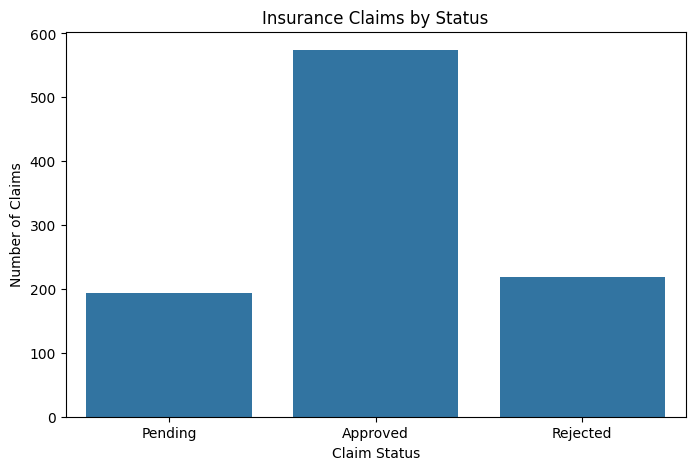

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=clean_claims,
    x="status"
)

plt.title("Insurance Claims by Status")
plt.xlabel("Claim Status")
plt.ylabel("Number of Claims")

plt.show()

Claim amount by category

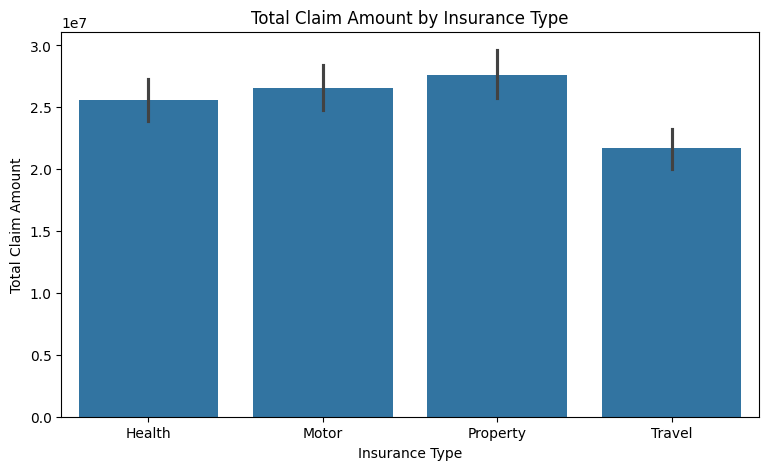

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=clean_claims,
    x="claim_type",
    y="claim_amount",
    estimator="sum"
)

plt.title("Total Claim Amount by Insurance Type")
plt.xlabel("Insurance Type")
plt.ylabel("Total Claim Amount")

plt.show()

Processing time analysis

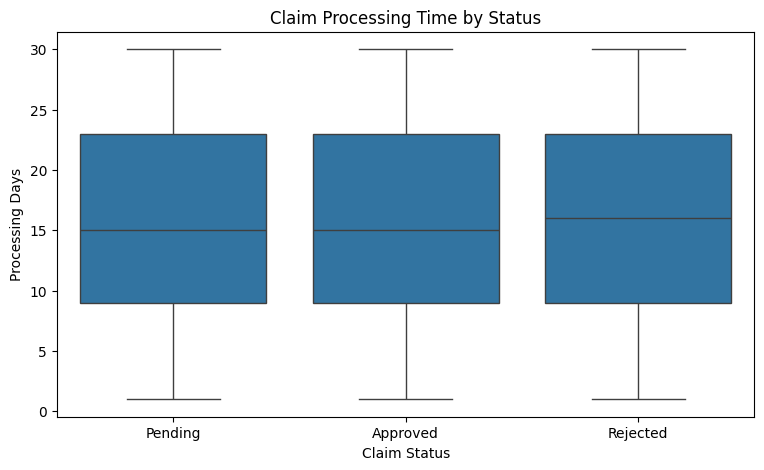

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=clean_claims,
    x="status",
    y="processing_days"
)

plt.title("Claim Processing Time by Status")
plt.xlabel("Claim Status")
plt.ylabel("Processing Days")

plt.show()

**SQL**

Create database

In [ ]:
# Create database connection
conn = sqlite3.connect("insurance_claims.db")

# Upload cleaned dataset into SQL table
clean_claims.to_sql(
    "insurance_claims",
    conn,
    if_exists="replace",
    index=False
)

print("Database and table created successfully!")

Database and table created successfully!


In [ ]:
query = """
SELECT
    claim_type,
    COUNT(*) AS total_claims,
    SUM(claim_amount) AS total_claim_amount,
    ROUND(AVG(claim_amount), 2) AS average_claim_amount
FROM insurance_claims
GROUP BY claim_type
ORDER BY total_claim_amount DESC;
"""

sql_result = pd.read_sql_query(query, conn)

display(sql_result)

,claim_type,total_claims,total_claim_amount,average_claim_amount
0,Property,263,27601804,104949.83
1,Motor,251,26600408,105977.72
2,Health,254,25593014,100759.90
3,Travel,217,21702036,100009.38


Find regions with the highest number of pending claims.

In [ ]:
query = """
SELECT
    region,
    COUNT(*) AS pending_claims,
    SUM(claim_amount) AS pending_amount
FROM insurance_claims
WHERE status = 'Pending'
GROUP BY region
ORDER BY pending_claims DESC;
"""

display(pd.read_sql_query(query, conn))

,region,pending_claims,pending_amount
0,Mumbai,43,5025900
1,Chennai,42,3641940
2,Hyderabad,41,3892540
3,Pune,37,4179228
4,Bangalore,28,3099781
5,Unknown,2,200777


Export cleaned data and reports

In [ ]:
# Export cleaned claims
clean_claims.to_csv(
    "clean_insurance_claims.csv",
    index=False
)

# Export records requiring investigation
issues.to_csv(
    "data_quality_issues.csv",
    index=False
)

# Export summary reports
claim_analysis.to_csv(
    "claim_type_summary.csv",
    index=False
)

region_analysis.to_csv(
    "region_summary.csv",
    index=False
)

# Close database connection
conn.close()

print("All project files exported successfully!")

All project files exported successfully!
